In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense,Flatten,Input
from tensorflow.keras.optimizers import SGD

In [4]:
train_data=pd.read_csv('train_data.csv')
test_data=pd.read_csv('test_data.csv')
y_train=train_data['label'].values
x_train=train_data.drop('label',axis=1).values

y_test=test_data['label'].values
x_test=test_data.drop('label',axis=1).values

In [5]:
x_train=x_train/255.0
x_test=x_test/255.0

In [6]:
num_pixels=x_train.shape[1]
model=Sequential([
    Input(shape=(num_pixels,)),
    Dense(256,activation='relu'),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

In [8]:
model.compile(optimizer=SGD(learning_rate=0.01),
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])

history=model.fit(x_train,y_train,epochs=11,
                 batch_size=64,validation_data=(x_test, y_test))

Epoch 1/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.5016 - loss: 1.4134 - val_accuracy: 0.3995 - val_loss: 1.6991
Epoch 2/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5090 - loss: 1.3944 - val_accuracy: 0.4677 - val_loss: 1.4759
Epoch 3/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5144 - loss: 1.3751 - val_accuracy: 0.4353 - val_loss: 1.5801
Epoch 4/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5216 - loss: 1.3601 - val_accuracy: 0.4706 - val_loss: 1.4926
Epoch 5/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5270 - loss: 1.3445 - val_accuracy: 0.4891 - val_loss: 1.4477
Epoch 6/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5309 - loss: 1.3312 - val_accuracy: 0.4679 - val_loss: 1.5076
Epoch 7/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5394 - loss: 1.3146 - val_accuracy: 0.4493 - val_loss: 1.6403
Epoch 8/11
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5410 - loss: 1.3020 - val_accuracy: 0

In [9]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print(f"Test Loss:{test_loss:.4f}")
print(f"Test Accuracy:{test_accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4538 - loss: 1.5183
Test Loss:1.5183
Test Accuracy:45.38%


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4538 - loss: 1.5183
Test Loss: 1.5183
Test Accuracy: 45.38%


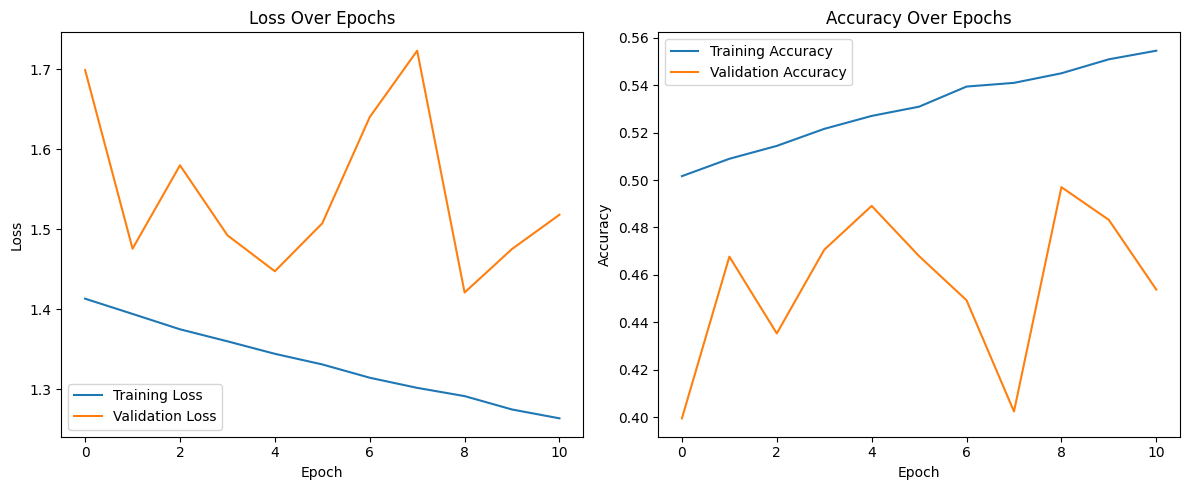

In [12]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()